## 在S形数据上训练简单的去噪扩散模型

### 1. 准备数据

shape of s: (10240, 2)


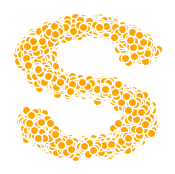

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_s_curve
import torch
import torch.nn.functional as F

s_curve, t = make_s_curve(10240, noise=0.1)
s_curve = s_curve[:,[0,2]] / 10.0  # 每个点取第0维和第2维, 再除以10
print("shape of s:", np.shape(s_curve))

data = s_curve.T
fig,ax = plt.subplots(figsize=(2, 2))
ax.scatter(*data, color='orange',edgecolor='white')
ax.axis('off')


dataset = torch.Tensor(s_curve).float()

### 2. 计算前向过程中的参数

In [2]:
# 准备好alpha(αt), beta(βt), αt^, 根号下αt^, 根号下(1-αt^)等值
num_steps = 100  # 设置步长

# 制定每一步的beta
betas = torch.linspace(-6, 6, num_steps).float() # 逐渐递增
betas = torch.sigmoid(betas)*(0.5e-2 - 1e-5)+1e-5  # β0,β1,...,βt

# 计算alpha、alpha_prod、alpha_prod_previous、alpha_bar_sqrt等变量的值
alphas = 1 - betas  # αt = 1 - βt
alphas_prod = alphas.cumprod(dim=0)  # αt^ = αt的累乘
# αt^往右平移一位, 原第t步的值为第t-1步的值, 第0步补1
alphas_prod_p = F.pad(alphas_prod[1:], (1, 0), value=1.)  # αt-1 ^
alphas_bar_sqrt = alphas_prod.sqrt()  # αt^ 开根号
one_minus_alphas_bar_log = torch.log(1 - alphas_prod)  # log(1-αt^)
one_minus_alphas_bar_sqrt = torch.sqrt(1 - alphas_prod)  # 根号下(1-αt^)

assert alphas.shape==alphas_prod.shape==alphas_prod_p.shape==alphas_bar_sqrt.shape==one_minus_alphas_bar_log.shape==one_minus_alphas_bar_sqrt.shape
print("all the same shape",betas.shape)

all the same shape torch.Size([100])


### 3. 计算任意时刻的x采样值，基于x_0和重参数化

In [3]:
def q_x(x_0, t):
    """
    作用：前向过程, 可以基于x[0]得到任意时刻t的x[t]
    输入：x_0:初始干净图像；t：采样步
    输出：x_t:第t步时的x_0已成为的样子
    """
    noise = torch.randn_like(x_0)  # noise为从正态分布中采样的随机噪声
    
    alphas_t = alphas_bar_sqrt[t]  # 根号下αt^
    alphas_1_m_t = one_minus_alphas_bar_sqrt[t]  # 根号下(1-αt^)
    return (alphas_t * x_0 + alphas_1_m_t * noise) # 在x[0]的基础上添加噪声

演示原始数据分布加噪100步后的结果，可观察到从S曲线在100步中逐渐变为高斯分布的过程：

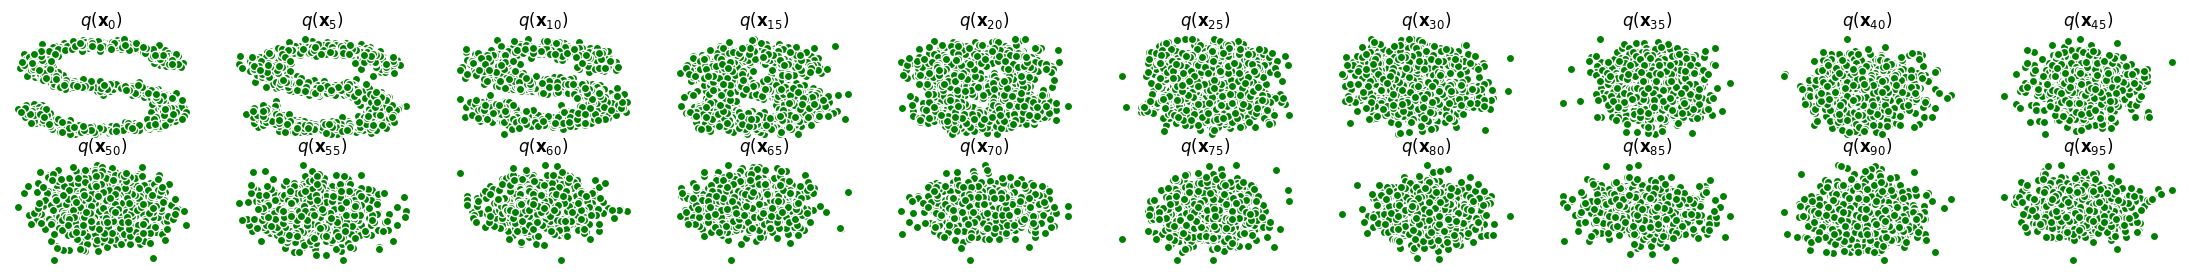

In [4]:
num_shows = 20
fig,axs = plt.subplots(2, 10, figsize=(28,3))
plt.rc('text',color='black')

for i in range(num_shows):
    j = i//10
    k = i%10
    q_i = q_x(dataset[::10], torch.tensor([i*num_steps//num_shows])) # 生成t时刻的采样数据
    axs[j,k].scatter(q_i[:,0], q_i[:,1], color='green', edgecolor='white')
    axs[j,k].set_axis_off()
    axs[j,k].set_title('$q(\mathbf{x}_{'+str(i*num_steps//num_shows)+'})$')

### 搭建去噪网络

MLP denosing network

In [5]:
import torch
import torch.nn as nn

class MLPDenosingBlock(nn.Module):
    def __init__(self, dim_in, dim_out):
        super().__init__()
        self.dim_in = dim_in
        self.dim_out = dim_out
        
        self.linear = nn.Linear(dim_in, dim_out)
        self.fn = nn.ReLU()

    def forward(self, x, t_emb):
        x = self.linear(x)
        x = x + t_emb # 在线性映射和激活函数中间插入时间条件
        x = self.fn(x)
        return x

class MLPDenosing(nn.Module):
    def __init__(self, n_steps, dim=128):
        super().__init__()
        self.dim = dim
        self.layers = nn.ModuleList(
            [
                MLPDenosingBlock(2, dim),
                MLPDenosingBlock(dim, dim),  
                MLPDenosingBlock(dim, dim),  
            ]
        )
        self.out_proj = nn.Linear(dim, 2)
        self.time_emb = nn.Embedding(n_steps, dim)
        
    def forward(self, x, t):
        # ndim对齐
        t_emb = self.time_emb(t).reshape(-1, self.dim)
        for block in self.layers:
            x = block(x, t_emb)       
        x = self.out_proj(x)
        return x

### DDPM
> Denoising Diffusion Probabilistic Models (https://arxiv.org/abs/2006.11239)

<center>
    <img src="attachment:9a0ab1bd-0fcb-4e4f-baaa-8e82a62a65b1.png" alt="image.png" style="width: 80%;"/>
<center/>

In [6]:
class DDPM:
    def __init__(self, n_steps, device):
        super().__init__()
        self.n_steps = n_steps  # 设置步长
        self.device= device
        
        self.model = MLPDenosing(n_steps=n_steps, dim=128).to(device)
        
        # 把上面算过的参数都复制过来，然后放到device上
        # 制定每一步的beta
        self.betas = torch.linspace(-6, 6, n_steps).float().to(device) # 逐渐递增
        self.betas = torch.sigmoid(self.betas)*(0.5e-2 - 1e-5)+1e-5  # β0,β1,...,βt
        
        # 计算alpha、alpha_prod、alpha_prod_previous、alpha_bar_sqrt等变量的值
        self.alphas = 1 - self.betas  # αt = 1 - βt
        self.alphas_sqrt = self.alphas.sqrt()
        self.alphas_prod = self.alphas.cumprod(dim=0)  # αt^ = αt的累乘
        # αt^往右平移一位, 原第t步的值为第t-1步的值, 第0步补1
        self.alphas_prod_p = F.pad(self.alphas_prod[1:], (1, 0), value=1.)  # αt-1 ^
        self.alphas_bar_sqrt = self.alphas_prod.sqrt()  # αt^ 开根号
        self.one_minus_alphas_bar_log = torch.log(1. - self.alphas_prod)  # log(1-αt^)
        self.one_minus_alphas_bar_sqrt = torch.sqrt(1. - self.alphas_prod)  # 根号下(1-αt^)

    def q_x(self, x_0, t):
        """
        从上面复制过来的前向传播函数，添加了返回的e_t用于计算loss
        作用：前向过程, 可以基于x[0]得到任意时刻t的x[t]
        输入：x_0:初始干净图像；t：采样步
        输出：x_t:第t步时的x_0已成为的样子
             e_t: 添加的噪声（用于计算loss）
        """
        t = t.reshape(-1, 1) # t和 x[n, 3]对齐
        noise = torch.randn_like(x_0)  # noise为从正态分布中采样的随机噪声
        
        alphas_t = self.alphas_bar_sqrt[t]  # 根号下αt^
        alphas_1_m_t = self.one_minus_alphas_bar_sqrt[t]  # 根号下(1-αt^)

        return alphas_t * x_0 + alphas_1_m_t * noise, noise

    
    def diffusion_loss(self, x_0):
        """
        对应上图Algorithm 1: Training
        参数： x_0: 输入样本，也就是干净的图
        """
        batch_size = x_0.shape[0]
        
        # 对一个batchsize样本生成随机的时刻t
        t = torch.randint(0, self.n_steps, size=(batch_size,), device=self.device)  # 在0~99内生成整数采样步
        
        # 构造模型的输入
        x_t, e_t = self.q_x(x_0, t)  # 前向过程：根号下αt^ * x0 + 根号下(1-αt^) * eps
        
        # 建模噪声
        output = self.model(x_t, t)  # 模型预测的是噪声, 噪声维度与x0一样大, [10000,2]
        
        # 与真实噪声一起计算误差，求平均值
        return (e_t - output).square().mean()

    @torch.no_grad()
    def p_sample(self, noise, n_steps):
        """
        作用：从x[T]恢复x[T-1]、x[T-2]、...x[0]
        输入：
            shape:数据大小,用于生成随机噪声
        输出：
            x_seq：一个序列的x, 即 x[T]、x[T-1]、x[T-2]、...x[0]
        """
        cur_x = noise
        x_seq = [cur_x]
        for i in reversed(range(n_steps)):
            cur_x = self._p_sample_step(cur_x, i)
            x_seq.append(cur_x)
        return x_seq

    @torch.no_grad()
    def _p_sample_step(self, x_t, t):
        """
        作用：采样一步
        输入：x_t, t
        输出：
            模型从x_t预测的x_{t-1}
        """
        t = torch.tensor([t], device=self.device)
        
        coeff = self.betas[t] / self.one_minus_alphas_bar_sqrt[t]  # 模型输出的系数：βt/根号下(1-αt^) = 1-αt/根号下(1-αt^)
       
        eps_theta = self.model(x_t, t)  # 模型的输出: εθ(xt, t)
            
        # 见algorithm-2
        mean = (1 / self.alphas_sqrt[t]) * (x_t - (coeff * eps_theta))   
        
        z = torch.randn_like(x_t)  # 对应公式中的 z
        
        sigma_t = self.betas[t].sqrt()  # 对应公式中的 σt 
        
        return mean + sigma_t * z 

### 训练

In [7]:
from tqdm import tqdm
print('Training model...')
batch_size = 1024
num_epoch = 4000
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ddpm = DDPM(num_steps, device)

optimizer = torch.optim.Adam(ddpm.model.parameters(), lr=1e-3) 
dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

x_seq_list = []

with tqdm(total=num_epoch) as pbar:
    for t in range(num_epoch):
        pbar.set_description(f'Epoch {t+1}')
        loss_ema = None
        for batch_x in dataloader:
            batch_x = batch_x.to(device)
            # 损失计算
            loss = ddpm.diffusion_loss(batch_x)
            optimizer.zero_grad()  # 梯度清零
            loss.backward()  # 损失回传
            if loss_ema is None:
                loss_ema = loss.item()
            else:
                loss_ema = 0.95 * loss_ema + 0.05 * loss.item()
            torch.nn.utils.clip_grad_norm_(ddpm.model.parameters(),1.)  # 梯度裁剪
            optimizer.step()
        pbar.set_postfix(loss=f'{loss_ema:.4f}')    

        if(t % 1000 == 0):
            n, d = dataset.shape
            noise = torch.randn((n // 10, d), device=device)  # 输入随机噪声，用1/10样本采样即可，节省空间
            x_seq = ddpm.p_sample(noise, num_steps)
            x_seq_list.append(x_seq)

        pbar.update(1)

Training model...


Epoch 4000: 100%|██████████████| 4000/4000 [02:01<00:00, 32.92it/s, loss=0.3117]


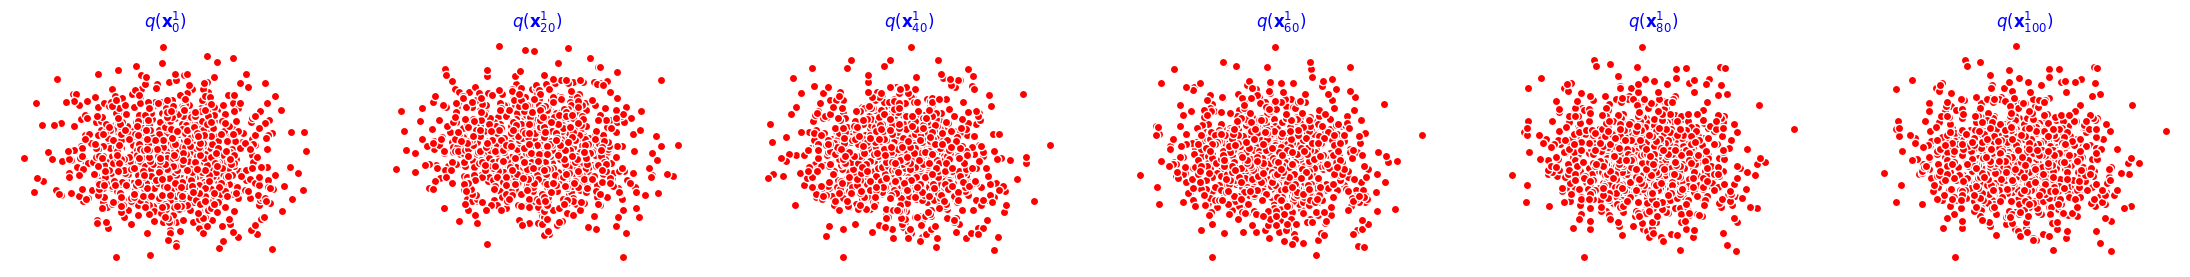

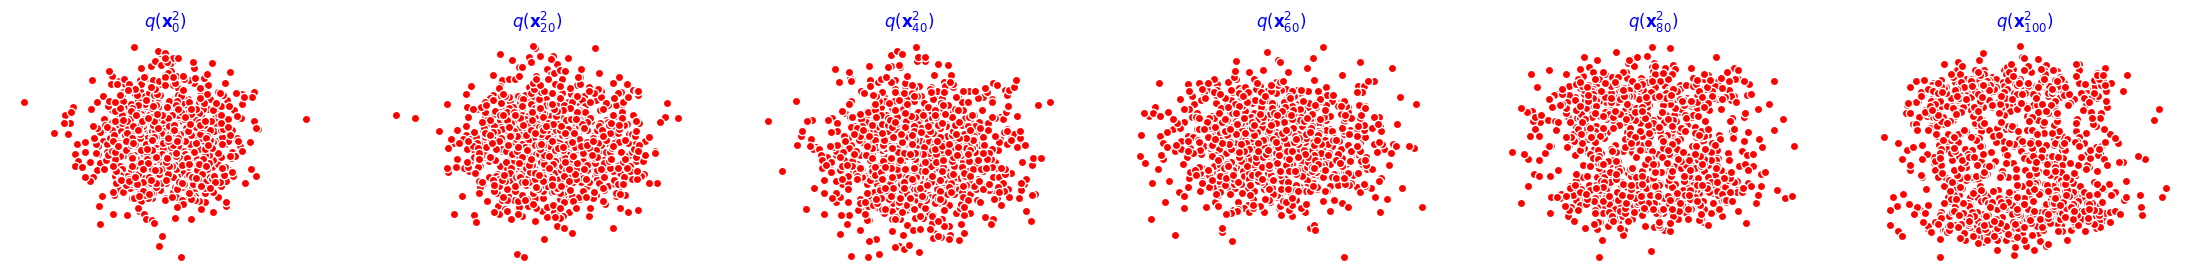

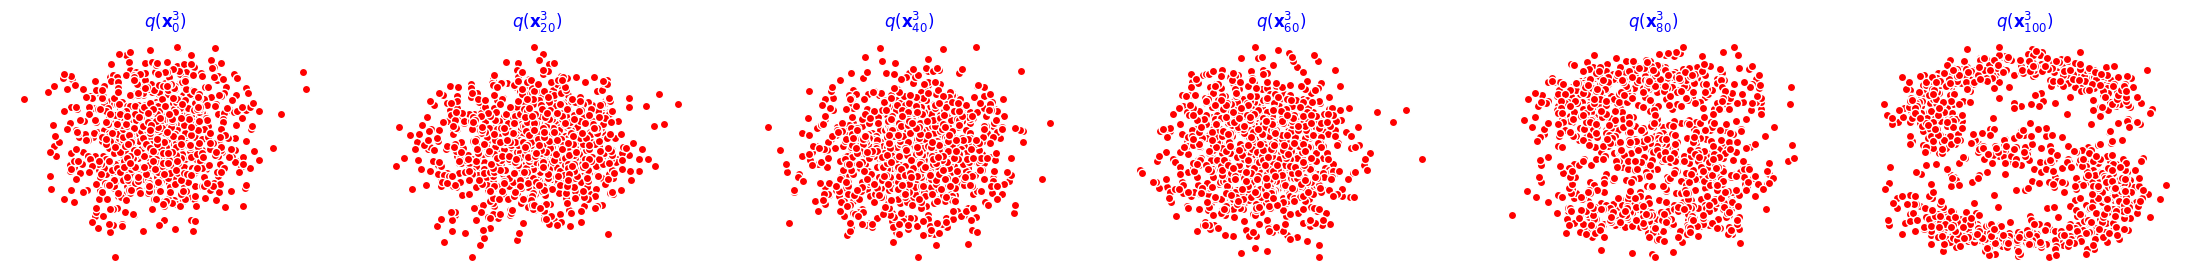

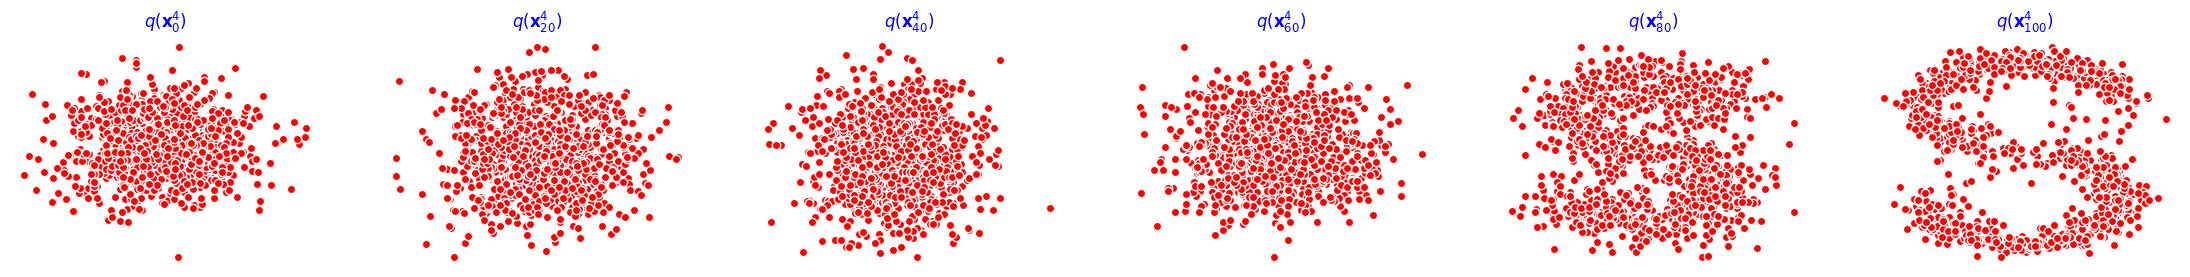

In [8]:
smp_step=20 # 每间隔20个点画一个图

# plot picture
plt.rc('text',color='blue')
for k, x_seq in enumerate(x_seq_list):
    x_seq = x_seq[::smp_step]
    fig, axs = plt.subplots(1, len(x_seq), figsize=(28,3))
    for i, cur_x in enumerate(x_seq):
        cur_x = cur_x.cpu()
        axs[i].scatter(cur_x[:,0],cur_x[:,1],color='red',edgecolor='white');
        axs[i].set_axis_off();
        axs[i].set_title('$q(\mathbf{x}_{'+str(i*smp_step)+'}^{'+str(k+1)+'})$')